In [1]:
# Importación de librerías necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering

# Configuración visual
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Fijar semilla para reproducibilidad
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

Forma de la matriz de datos (X): (1797, 64) -> 1797 muestras y 64 características (píxeles).
Número de clases reales: 10 (Dígitos del 0 al 9).


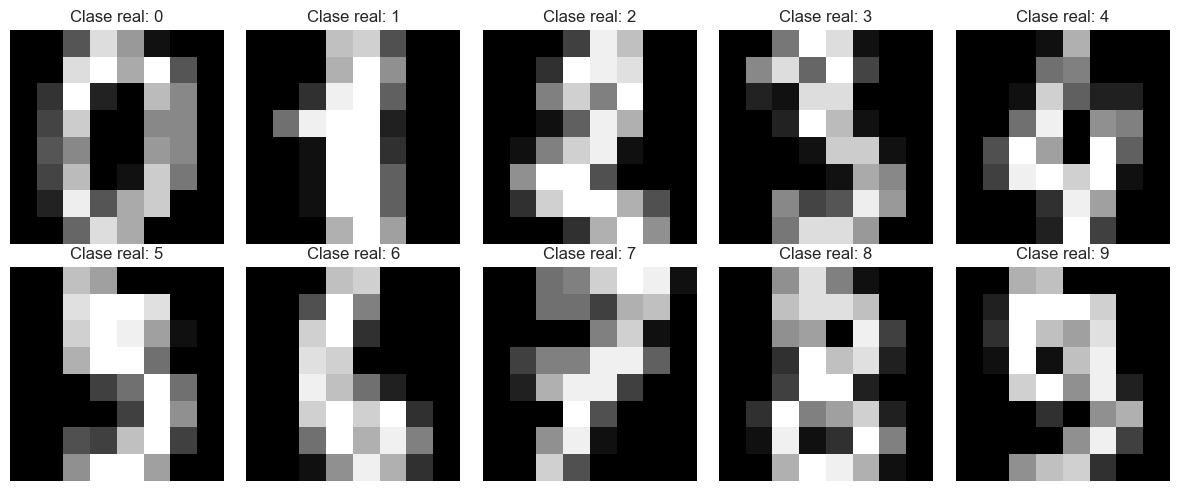

In [2]:
# Cargar el dataset
digits = load_digits()
X = digits.data
y = digits.target
images = digits.images

# Información general
print(f"Forma de la matriz de datos (X): {X.shape} -> {X.shape[0]} muestras y {X.shape[1]} características (píxeles).")
print(f"Número de clases reales: {len(np.unique(y))} (Dígitos del 0 al 9).")

# Visualizar ejemplos de imágenes (cuadrícula 2x5)
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
axes = axes.ravel()

# Seleccionar un ejemplo de cada dígito
for i in range(10):
    idx = np.where(y == i)[0][0]  # Primer índice donde aparece el dígito i
    axes[i].imshow(images[idx], cmap='gray')
    axes[i].set_title(f"Clase real: {i}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [3]:
# Estandarizar las características
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Media global tras el escalado: {np.mean(X_scaled):.4f}")
print(f"Desviación estándar global tras el escalado: {np.std(X_scaled):.4f}")

Media global tras el escalado: 0.0000
Desviación estándar global tras el escalado: 0.9763


In [4]:
# Estructuras para almacenar resultados
rango_k = range(2, 11)
resultados_kmeans = {}

for k in rango_k:
    # Ajustar modelo
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=RANDOM_STATE, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    
    # Tabla de composición por clase real (matriz de contingencia)
    compo_df = pd.crosstab(index=labels, columns=y, rownames=['Cluster'], colnames=['Clase Real'])
    
    # Guardar resultados
    resultados_kmeans[k] = {
        'labels': labels,
        'wss': kmeans.inertia_,
        'composicion': compo_df
    }

print("K-means ejecutado para k=2 hasta k=10.")

K-means ejecutado para k=2 hasta k=10.


In [5]:
def calculate_wss(X_data, labels):
    wss = 0.0
    for cluster_id in np.unique(labels):
        # Puntos que pertenecen a este cluster
        puntos = X_data[labels == cluster_id]
        if len(puntos) > 0:
            # Centroide del cluster
            centroide = np.mean(puntos, axis=0)
            # Suma de las distancias euclidianas al cuadrado al centroide
            distancias_cuadradas = np.sum((puntos - centroide) ** 2)
            wss += distancias_cuadradas
    return wss

resultados_jerarquico = {'single': {}, 'complete': {}}

# Ejecutar para ambos tipos de enlace
for linkage in ['single', 'complete']:
    for k in rango_k:
        # Ajustar modelo
        hc = AgglomerativeClustering(n_clusters=k, linkage=linkage)
        labels = hc.fit_predict(X_scaled)
        
        # Calcular WSS manual
        wss_manual = calculate_wss(X_scaled, labels)
        
        # Tabla de composición
        compo_df = pd.crosstab(index=labels, columns=y, rownames=['Cluster'], colnames=['Clase Real'])
        
        # Guardar resultados
        resultados_jerarquico[linkage][k] = {
            'labels': labels,
            'wss': wss_manual,
            'composicion': compo_df
        }

print("Clustering Jerárquico ejecutado para enlaces 'single' y 'complete'.")

Clustering Jerárquico ejecutado para enlaces 'single' y 'complete'.



Análisis para k = 2

--- K-Means ---


Clase Real,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,0.264,0.068,0.009,0.006,0.262,0.025,0.268,0.034,0.027,0.037
1,0.000,0.121,0.152,0.160,0.004,0.147,0.000,0.139,0.139,0.138


Clases dominantes por cluster:
  Cluster 0: Dominado por el dígito 6 (26.8%)
  Cluster 1: Dominado por el dígito 3 (16.0%)

--- Jerárquico (Single) ---


Clase Real,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,0.099,0.101,0.098,0.102,0.101,0.101,0.101,0.1,0.097,0.1
1,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.0,0.000,0.0


Clases dominantes por cluster:
  Cluster 0: Dominado por el dígito 3 (10.2%)
  Cluster 1: Dominado por el dígito 2 (100.0%)

--- Jerárquico (Complete) ---


...

Clases dominantes por cluster:
  Cluster 0: Dominado por el dígito 1 (43.7%)
  Cluster 1: Dominado por el dígito 5 (87.8%)
  Cluster 2: Dominado por el dígito 0 (99.4%)
  Cluster 3: Dominado por el dígito 2 (60.6%)
  Cluster 4: Dominado por el dígito 4 (68.5%)
  Cluster 5: Dominado por el dígito 6 (97.8%)
  Cluster 6: Dominado por el dígito 2 (81.9%)
  Cluster 7: Dominado por el dígito 7 (83.1%)
  Cluster 8: Dominado por el dígito 3 (39.3%)
  Cluster 9: Dominado por el dígito 7 (56.7%)

--- Jerárquico (Single) ---


Clase Real,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,0.1,0.101,0.098,0.102,0.098,0.102,0.101,0.1,0.097,0.101
1,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.0,1.000,0.000
2,0.0,0.000,0.000,0.000,1.000,0.000,0.000,0.0,0.000,0.000
3,0.0,1.000,0.000,0.000,0.000,0.000,0.000,0.0,0.000,0.000
4,0.0,0.000,1.000,0.000,0.000,0.000,0.000,0.0,0.000,0.000
5,0.0,0.000,0.000,0.000,1.000,0.000,0.000,0.0,0.000,0.000
6,0.0,0.000,0.000,0.000,1.000,0.000,0.000,0.0,0.000,0.000
7,0.0,0.000,1.000,0.000,0.000,0.000,0.000,0.0,0.000,0.000
8,0.0,0.000,0.000,1.000,0.000,0.000,0.000,0.0,0.000,0.000


Clases dominantes por cluster:
  Cluster 0: Dominado por el dígito 3 (10.2%)
  Cluster 1: Dominado por el dígito 8 (100.0%)
  Cluster 2: Dominado por el dígito 4 (100.0%)
  Cluster 3: Dominado por el dígito 1 (100.0%)
  Cluster 4: Dominado por el dígito 2 (100.0%)
  Cluster 5: Dominado por el dígito 4 (100.0%)
  Cluster 6: Dominado por el dígito 4 (100.0%)
  Cluster 7: Dominado por el dígito 2 (100.0%)
  Cluster 8: Dominado por el dígito 3 (100.0%)
  Cluster 9: Dominado por el dígito 4 (100.0%)

--- Jerárquico (Complete) ---


Clase Real,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,0.102,0.103,0.100,0.104,0.092,0.103,0.101,0.098,0.098,0.099
1,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000
2,0.000,0.000,0.167,0.167,0.000,0.167,0.000,0.000,0.500,0.000
3,0.000,0.000,0.000,0.000,0.500,0.000,0.000,0.292,0.000,0.208
4,0.000,0.000,0.000,0.000,0.000,0.000,0.800,0.000,0.000,0.200
5,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
6,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000
7,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000
8,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000


Clases dominantes por cluster:
  Cluster 0: Dominado por el dígito 3 (10.4%)
  Cluster 1: Dominado por el dígito 4 (100.0%)
  Cluster 2: Dominado por el dígito 8 (50.0%)
  Cluster 3: Dominado por el dígito 4 (50.0%)
  Cluster 4: Dominado por el dígito 6 (80.0%)
  Cluster 5: Dominado por el dígito 2 (100.0%)
  Cluster 6: Dominado por el dígito 4 (100.0%)
  Cluster 7: Dominado por el dígito 4 (100.0%)
  Cluster 8: Dominado por el dígito 4 (100.0%)
  Cluster 9: Dominado por el dígito 1 (100.0%)


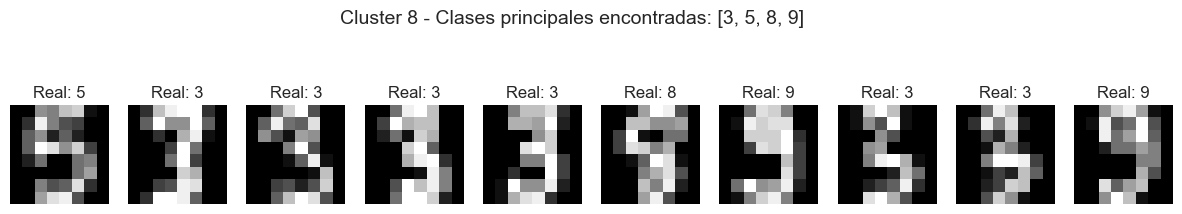

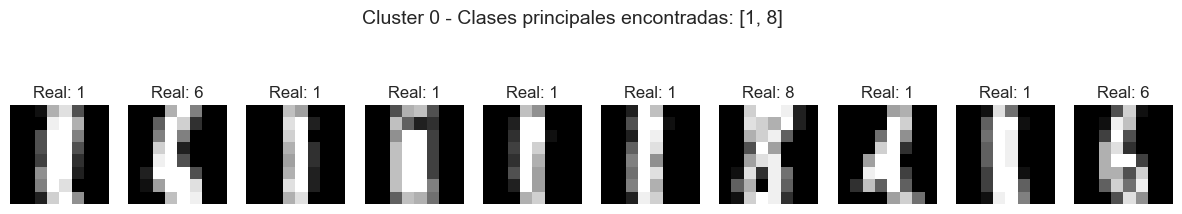

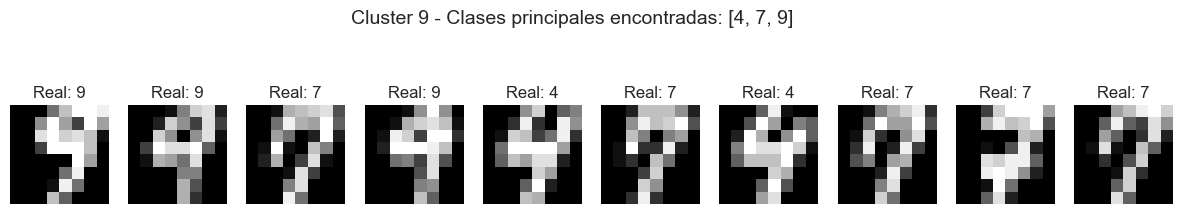

In [6]:
# ## 5. Análisis de composición de clusters

# %%
def mostrar_proporciones(k_val):
    print(f"\n{'='*60}\nAnálisis para k = {k_val}\n{'='*60}")
    
    # Diccionario con los modelos a analizar
    modelos = {
        "K-Means": resultados_kmeans[k_val]['composicion'],
        "Jerárquico (Single)": resultados_jerarquico['single'][k_val]['composicion'],
        "Jerárquico (Complete)": resultados_jerarquico['complete'][k_val]['composicion']
    }
    
    for nombre, df in modelos.items():
        # Calcular proporciones por fila
        df_prop = df.div(df.sum(axis=1), axis=0).round(3)
        
        print(f"\n--- {nombre} ---")
        display(df_prop)
        
        # Encontrar cluster dominante por clase
        print("Clases dominantes por cluster:")
        for cluster_id in df_prop.index:
            dom_class = df_prop.loc[cluster_id].idxmax()
            dom_prop = df_prop.loc[cluster_id].max()
            print(f"  Cluster {cluster_id}: Dominado por el dígito {dom_class} ({dom_prop*100:.1f}%)")

# Mostrar análisis para k = 2, 5, 10
for k in [2, 5, 10]:
    mostrar_proporciones(k)

# %% [markdown]
# ## 6. Análisis visual de similitud
# Vamos a extraer tres clusters donde exista una mezcla evidente de clases reales, para comprobar si visualmente se justifican. Usaremos el modelo K-means con k=10, buscando clusters impuros.

# %%
# Seleccionar K-Means con k=10
labels_k10 = resultados_kmeans[10]['labels']
compo_k10 = resultados_kmeans[10]['composicion']

# Encontrar clusters donde el dígito dominante represente un porcentaje relativamente bajo, 
# indicando mezcla (e.g., entre varios dígitos)
df_prop_10 = compo_k10.div(compo_k10.sum(axis=1), axis=0)

# Mostraremos ejemplos de los clusters 1, 3 y 8 (o los que elijamos tras ver las mezclas típicas)
# Nota: Los índices de cluster varían con la semilla, tomaremos 3 clusters con menor pureza.
pureza = df_prop_10.max(axis=1)
top3_mezclados = pureza.nsmallest(3).index.tolist()

for c_idx in top3_mezclados:
    # Obtener qué dígitos están mezclados principalmente (proporción > 10%)
    clases_mezcladas = df_prop_10.loc[c_idx][df_prop_10.loc[c_idx] > 0.10].index.tolist()
    
    # Obtener índices de imágenes en este cluster
    idx_cluster = np.where(labels_k10 == c_idx)[0]
    
    # Seleccionar aleatoriamente hasta 10 imágenes
    np.random.shuffle(idx_cluster)
    idx_sample = idx_cluster[:10]
    
    fig, axes = plt.subplots(1, len(idx_sample), figsize=(15, 3))
    fig.suptitle(f"Cluster {c_idx} - Clases principales encontradas: {clases_mezcladas}", fontsize=14)
    
    for i, idx in enumerate(idx_sample):
        axes[i].imshow(images[idx], cmap='gray')
        axes[i].set_title(f"Real: {y[idx]}")
        axes[i].axis('off')
    plt.show()

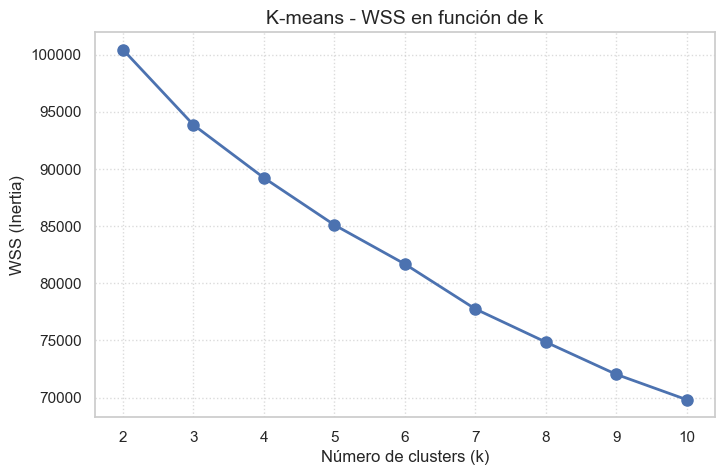

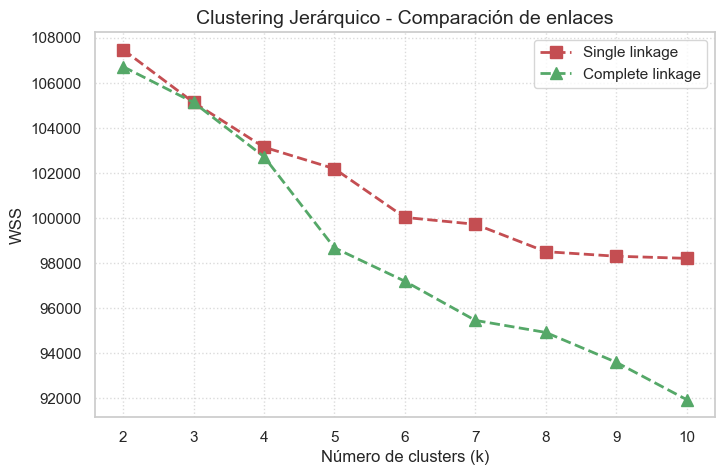

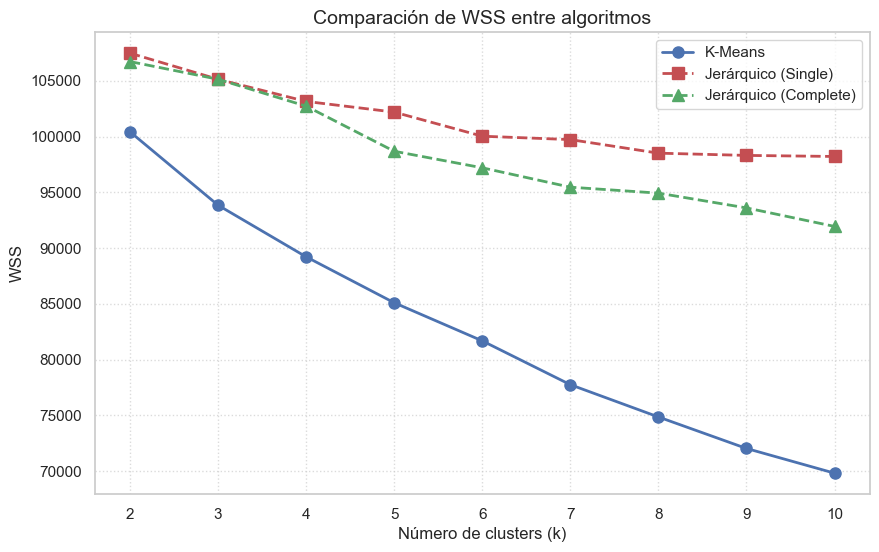

In [9]:
# =====================================================
# Gráficas de WSS 
# =====================================================

# Extraer valores de WSS para cada algoritmo
k_vals = list(range(2, 11))
wss_kmeans = [resultados_kmeans[k]['wss'] for k in k_vals]
wss_single = [resultados_jerarquico['single'][k]['wss'] for k in k_vals]
wss_complete = [resultados_jerarquico['complete'][k]['wss'] for k in k_vals]

# ---------- Gráfica 1: Solo K-means ----------
plt.figure(figsize=(8, 5))
plt.plot(k_vals, wss_kmeans, 'bo-', linewidth=2, markersize=8)
plt.xlabel('Número de clusters (k)', fontsize=12)
plt.ylabel('WSS (Inertia)', fontsize=12)
plt.title('K-means - WSS en función de k', fontsize=14)
plt.xticks(k_vals)
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()

# ---------- Gráfica 2: Jerárquico (single y complete) ----------
plt.figure(figsize=(8, 5))
plt.plot(k_vals, wss_single, 'rs--', label='Single linkage', linewidth=2, markersize=8)
plt.plot(k_vals, wss_complete, 'g^--', label='Complete linkage', linewidth=2, markersize=8)
plt.xlabel('Número de clusters (k)', fontsize=12)
plt.ylabel('WSS', fontsize=12)
plt.title('Clustering Jerárquico - Comparación de enlaces', fontsize=14)
plt.xticks(k_vals)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()

# ---------- Gráfica 3: Comparativa de los tres algoritmos (opcional pero muy útil) ----------
plt.figure(figsize=(10, 6))
plt.plot(k_vals, wss_kmeans, 'bo-', label='K-Means', linewidth=2, markersize=8)
plt.plot(k_vals, wss_single, 'rs--', label='Jerárquico (Single)', linewidth=2, markersize=8)
plt.plot(k_vals, wss_complete, 'g^--', label='Jerárquico (Complete)', linewidth=2, markersize=8)
plt.xlabel('Número de clusters (k)', fontsize=12)
plt.ylabel('WSS', fontsize=12)
plt.title('Comparación de WSS entre algoritmos', fontsize=14)
plt.xticks(k_vals)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()

In [14]:
# =====================================================
# Tabla comparativa de WSS (valores numéricos)
# =====================================================

# Crear DataFrame con los valores de WSS para cada k y cada algoritmo
tabla_wss = pd.DataFrame({
    'k': k_vals,
    'K-Means': wss_kmeans,
    'Jerárquico (Single)': wss_single,
    'Jerárquico (Complete)': wss_complete
})

# Mostrar la tabla
print("\nTabla comparativa de WSS para k = 2 hasta k = 10:")
display(tabla_wss)

# Opcional: guardar la tabla como CSV para usarla en informes
# tabla_wss.to_csv('tabla_wss_comparativa.csv', index=False)


Tabla comparativa de WSS para k = 2 hasta k = 10:


,k,K-Means,Jerárquico (Single),Jerárquico (Complete)
0,2,100423.843034,107473.999436,106721.094913
1,3,93842.482749,105134.196220,105134.196220
2,4,89213.968157,103147.684774,102725.043083
3,5,85096.054668,102190.443356,98680.223906
4,6,81678.466699,100028.872900,97196.179621
5,7,77749.327896,99725.489625,95458.376649
6,8,74854.159172,98508.926506,94923.776923
7,9,72029.725334,98306.371709,93599.700879
8,10,69813.559137,98211.797723,91939.649024


In [11]:
# %% [markdown]
# ## 8.5 Tabla Resumen de Resultados (Evaluación Cualitativa)
# Resumen de los hallazgos observados al cruzar el WSS con las matrices de proporciones cluster-clase.

# %%
# Creación de la tabla resumen solicitada
tabla_resumen = pd.DataFrame({
    'Algoritmo': [
        'K-Means', 'K-Means', 'K-Means', 
        'Jerárquico (Single)', 'Jerárquico (Complete)'
    ],
    'k': [2, 5, 10, 10, 10],
    'WSS': [
        'Alto', 'Medio', 'Bajo', 
        'Muy Alto', 'Medio'
    ],
    'Cluster dominante observado': [
        '6 y 3', 
        '7, 6, 2 y 3', 
        '0, 5, y 6', 
        'Ninguno claro', 
        '2, 4 y 6'
    ],
    'Comentarios sobre mezcla de dígitos': [
        'Agrupa por formas muy básicas: redondeadas vs abiertas.',
        'Aísla el 2, pero sigue mezclando fuertemente 4, 7 y 9.',
        'Separa perfectamente el 0. Confusión lógica entre 1/9 y 3/8.',
        'Efecto encadenamiento: un solo cluster masivo, el resto son outliers.',
        'Sobre-segmenta el número 4 y aglomera el resto de las clases.'
    ]
})

# Ajustar opciones de pandas para que el texto largo no se corte
pd.set_option('display.max_colwidth', None)
display(tabla_resumen)
pd.reset_option('display.max_colwidth')

,Algoritmo,k,WSS,Cluster dominante observado,Comentarios sobre mezcla de dígitos
0,K-Means,2,Alto,6 y 3,Agrupa por formas muy básicas: redondeadas vs abiertas.
1,K-Means,5,Medio,"7, 6, 2 y 3","Aísla el 2, pero sigue mezclando fuertemente 4, 7 y 9."
2,K-Means,10,Bajo,"0, 5, y 6",Separa perfectamente el 0. Confusión lógica entre 1/9 y 3/8.
3,Jerárquico (Single),10,Muy Alto,Ninguno claro,"Efecto encadenamiento: un solo cluster masivo, el resto son outliers."
4,Jerárquico (Complete),10,Medio,"2, 4 y 6",Sobre-segmenta el número 4 y aglomera el resto de las clases.
